# Probabilistic programming

- This notebook walks through the Bayesian modeling workflow in `pymc`:
  checking, comparing, and averaging models, then the inference engines
  behind them and the diagnostics for their convergence
- The pedagogical arc:
  - Posterior predictive checks and Bayesian p-values for a linear and a
    quadratic model
  - Overfitting, and out-of-sample predictive accuracy with WAIC and PSIS-LOO
  - Comparing and averaging models
  - Mixture models: marginalizing over a discrete latent variable
  - Inference engines: grid approximation, Monte Carlo, and the Metropolis
    sampler
  - Diagnosing convergence: centered vs non-centered parametrization, rank
    plots, R-hat, effective sample size, and divergences

In [1]:
%load_ext autoreload
%autoreload 2

import logging

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import scipy.stats as stats

In [2]:
import helpers.hnotebook as hnotebook
import helpers.htutorial as ut

import L07_02_probabilistic_programming_utils as utils

# Initialize notebook configuration and logging.
hnotebook.config_notebook()
_LOG = logging.getLogger(__name__)
utils.init_loggers(_LOG)

# Convert `display` into `print()` when running outside IPython.
try:
    from IPython.display import display
except ImportError:
    display = print  # type: ignore

INFO  > /venv/lib/python3.12/site-packages/ipykernel_launcher.py -f /root/.local/share/jupyter/runtime/kernel-5183b085-8bc8-48f3-a4a0-b9c1b04afdd5.json


# Part 1: Posterior Predictive Checks

## Cell 1.1: Loading and preparing the data

**Goal**
- Load a synthetic, mostly-linear dataset, and build the polynomial
  feature rows a linear and a quadratic model will each be fit on

**Implementation**
- Reads `L07_data/dummy.csv`, stacks `x**i` for `i` in `1..order`, and
  standardizes both the features and the target to mean 0, std 1

In [3]:
dir_name = "./L07_data"
!ls $dir_name

anscombe.csv	     chemical_shifts_theo_exp.csv  islands.csv
anscombe_3.csv	     coal.csv			   penguins.csv
babies.csv	     dummy.csv			   pigs.csv
bikes.csv	     fish.csv			   redwood.csv
bikes_full.csv	     football_players.csv	   space_flu.csv
body_fat.csv	     horseshoe_crab.csv		   tips.csv
body_fat_full.csv    howell.csv
chemical_shifts.csv  iris.csv


In [4]:
# Load some data: it's mainly a linear relationship with some noise.
dummy_data = np.loadtxt(dir_name + "/dummy.csv")
x = dummy_data[:, 0]
y = dummy_data[:, 1]

# Transform the data applying various powers and stacking the data, so that
# we have different rows with different predicted variables.
order = 2
x_p = np.vstack([x**i for i in range(1, order + 1)])
display(pd.DataFrame(x_p))

# Normalize all the data.
x_c = (x_p - x_p.mean(axis=1, keepdims=True)) / x_p.std(axis=1, keepdims=True)
y_c = (y - y.mean()) / y.std()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32
0,-1.081000,-0.888000,-0.623000,-0.4800,-0.505000,-0.345000,0.052000,0.061000,0.215000,0.395000,0.643000,0.871000,0.776000,0.833000,1.224000,1.30,1.563000,1.669000,1.967000,1.9500,2.0300,2.284000,2.534000,2.531000,2.765000,2.913000,3.168000,3.119000,3.385000,3.488000,3.538000,3.90,3.9700
1,1.168561,0.788544,0.388129,0.2304,0.255025,0.119025,0.002704,0.003721,0.046225,0.156025,0.413449,0.758641,0.602176,0.693889,1.498176,1.69,2.442969,2.785561,3.869089,3.8025,4.1209,5.216656,6.421156,6.405961,7.645225,8.485569,10.036224,9.728161,11.458225,12.166144,12.517444,15.21,15.7609


## Cell 1.2: Visualizing the raw relationship

**Goal**
- Look at the order-0 feature (the raw, normalized `x`) against `y`
  before fitting anything

In [6]:
import os
os.environ["CSFY_GIT_ROOT_PATH"] = "/tmp/msml610"
ut.FIG_DIR = "/tmp/msml610/lectures_source/figures"
os.makedirs(ut.FIG_DIR, exist_ok=True)

INFO  ![](/tmp/msml610/lectures_source/figures/Lesson07.Comparing_models.data.png)


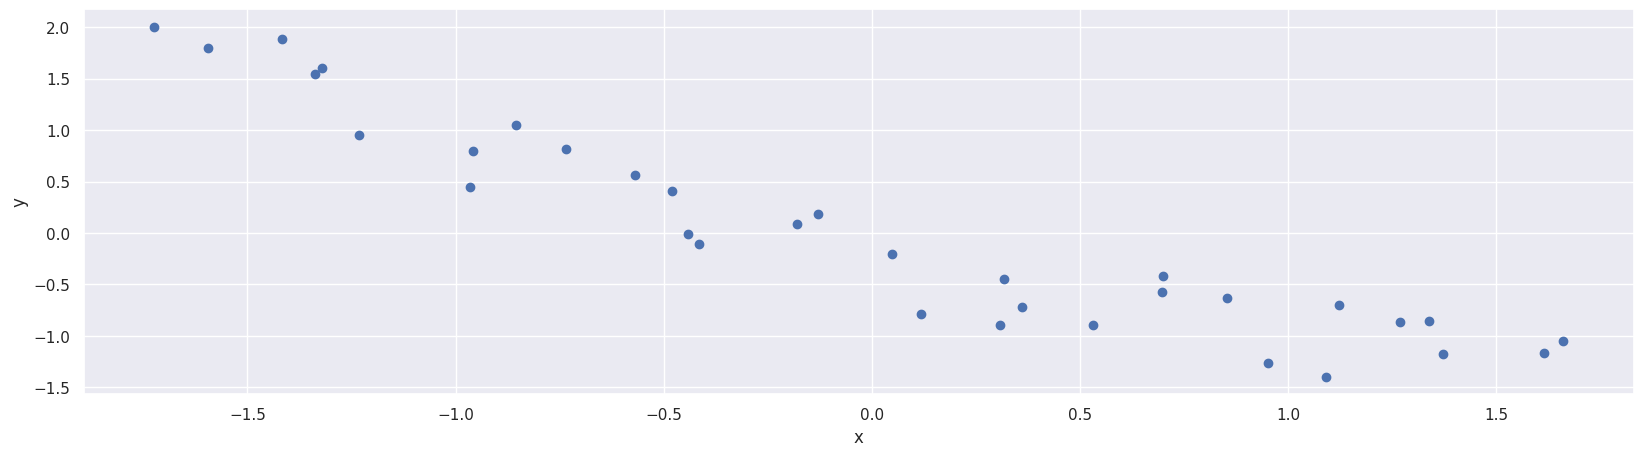

In [7]:
# Plot the 0-order data (i.e., the original one).
plt.scatter(x_c[0], y_c)
plt.xlabel("x")
plt.ylabel("y")
ut.save_plt("Lesson07.Comparing_models.data.png")

## Cell 1.3: Fitting linear and quadratic models

**Goal**
- Fit a linear and a quadratic Bayesian regression on the same data, so
  their posterior predictive fit can be compared

**Implementation**
- `model_l`: $\mu = \alpha + \beta x$, `model_p`: $\mu = \alpha + \beta_1
  x + \beta_2 x^2$, both with a `Normal` likelihood and `pm.sample()`

In [8]:
# Linear model.
with pm.Model() as model_l:
    # mu = alpha + beta * x
    alpha = pm.Normal("alpha", mu=0, sigma=1)
    beta = pm.Normal("beta", mu=0, sigma=10)
    mu = alpha + beta * x_c[0]
    #
    sigma = pm.HalfNormal("sigma", 5)
    #
    y_pred = pm.Normal("y_pred", mu=mu, sigma=sigma, observed=y_c)
    #
    idata_l = pm.sample(2000, idata_kwargs={"log_likelihood": True})
    idata_l = pm.sample_posterior_predictive(idata_l, extend_inferencedata=True)

# Quadratic model.
with pm.Model() as model_p:
    # mu = alpha + beta_1 * x + beta_2 * x^2
    alpha = pm.Normal("alpha", mu=0, sigma=1)
    # Beta is a 2-dim vector.
    beta = pm.Normal("beta", mu=0, sigma=10, shape=order)
    mu = alpha + pm.math.dot(beta, x_c)
    #
    sigma = pm.HalfNormal("sigma", 5)
    #
    y_pred = pm.Normal("y_pred", mu=mu, sigma=sigma, observed=y_c)
    #
    idata_q = pm.sample(2000, idata_kwargs={"log_likelihood": True})
    idata_q = pm.sample_posterior_predictive(idata_q, extend_inferencedata=True)

Initializing NUTS using jitter+adapt_diag...


INFO  Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


INFO  Multiprocess sampling (4 chains in 4 jobs)


NUTS: [alpha, beta, sigma]


INFO  NUTS: [alpha, beta, sigma]


... (14 outputs left out)

INFO  Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 1 seconds.


Sampling: [y_pred]


INFO  Sampling: [y_pred]


Output()

## Cell 1.4: Comparing the fitted models against the data

**Goal**
- Plot both models' mean-posterior curve against the data, to see the
  difference a quadratic term makes

**Implementation**
- Extracts posterior means for `alpha`/`beta` from each `idata` via
  `az.extract()`, then evaluates each curve over a dense `x` grid

In [9]:
import os
os.environ["CSFY_GIT_ROOT_PATH"] = "/tmp/msml610"

import helpers.htutorial as ut
ut.FIG_DIR = "/tmp/msml610/lectures_source/figures"
os.makedirs(ut.FIG_DIR, exist_ok=True)

linear model: alpha_l_post=-0.0019, beta_l_post=-0.94
quadratic model: alpha_p_post=-0.00046, beta_post[0]=-1.5, beta_post[1]=0.57
INFO  ![](/tmp/msml610/lectures_source/figures/Lesson07.Comparing_models.model_fit.png)


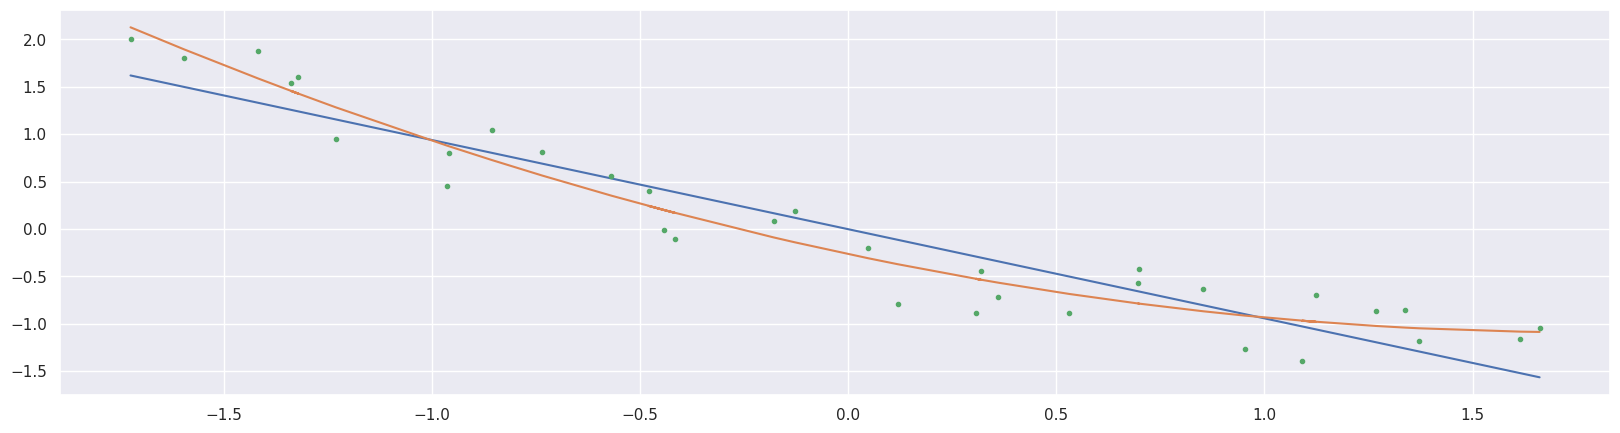

In [10]:
# Sample the x space uniformly with 100 samples.
x_new = np.linspace(x_c[0].min(), x_c[0].max(), 100)

# Posterior.
posterior_l = az.extract(idata_l)
posterior_p = az.extract(idata_q)

# Compute the mean posterior of the linear model.
alpha_l_post = posterior_l["alpha"].mean().item()
beta_l_post = posterior_l["beta"].mean().item()
print(
    f"linear model: alpha_l_post={alpha_l_post:.2g}, beta_l_post={beta_l_post:.2g}"
)
y_l_post = alpha_l_post + beta_l_post * x_new

# Plot the mean posterior of the linear model.
plt.plot(x_new, y_l_post, "C0", label="linear model")

# Quadratic model.
alpha_p_post = posterior_p["alpha"].mean().item()
beta_p_post = posterior_p["beta"].mean("sample")
print(
    f"quadratic model: alpha_p_post={alpha_p_post:.2g}, "
    f"beta_post[0]={beta_p_post[0]:.2g}, beta_post[1]={beta_p_post[1]:.2g}"
)
y_p_post = alpha_p_post + np.dot(beta_p_post, x_c)
plt.plot(x_c[0], y_p_post, "C1", label="quadratic model")

# Plot data.
plt.plot(x_c[0], y_c, "C2.")
ut.save_plt("Lesson07.Comparing_models.model_fit.png")

## Cell 1.5: Posterior predictive check plots

**Goal**
- Check each model's fit by comparing its posterior-predictive samples
  against the observed data

**Implementation** `az.plot_ppc(idata, num_pp_samples=100, ...)`
- Overlays 100 posterior-predictive draws on the observed data's density,
  for the linear and the quadratic model in turn

INFO  ![](/tmp/msml610/lectures_source/figures/Lesson07.Comparing_models.lin_model_PPC.png)


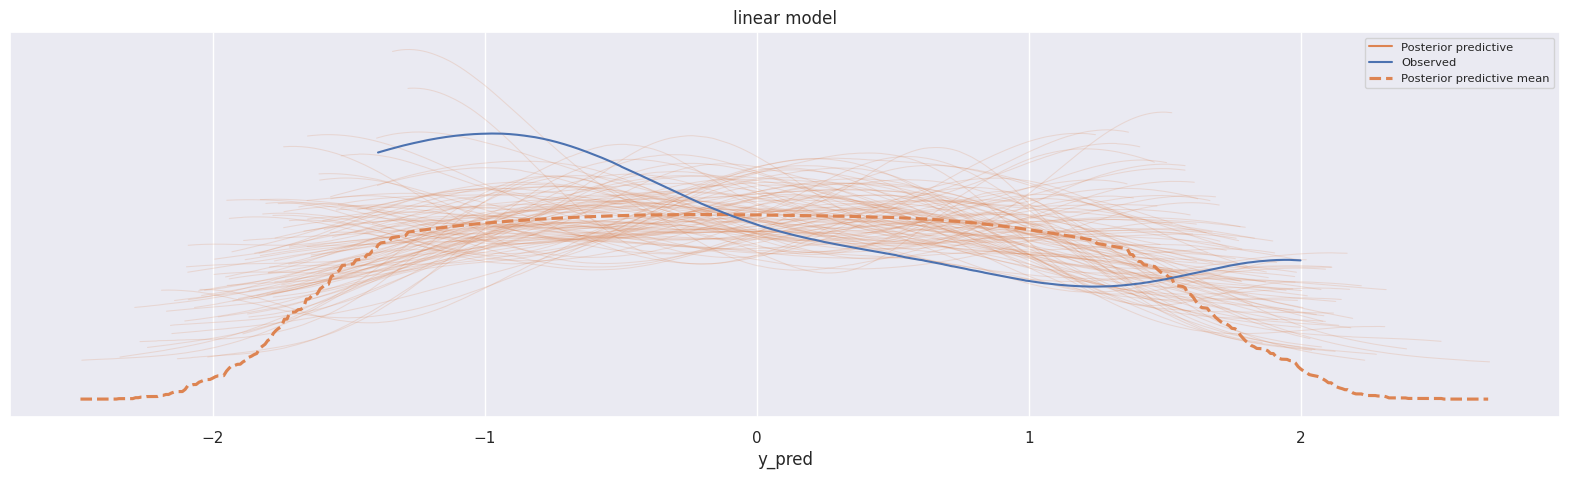

In [11]:
az.plot_ppc(idata_l, num_pp_samples=100, colors=["C1", "C0", "C1"])
plt.title("linear model")
ut.save_plt("Lesson07.Comparing_models.lin_model_PPC.png")

INFO  ![](/tmp/msml610/lectures_source/figures/Lesson07.Comparing_models.quadr_model_PPC.png)


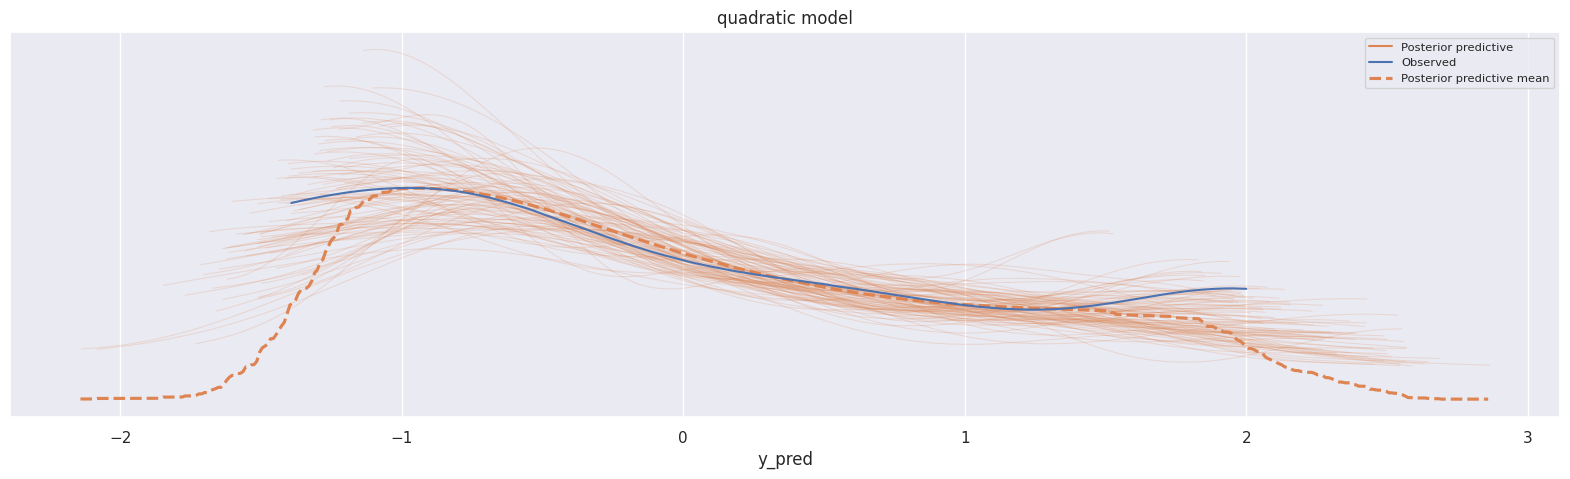

In [12]:
az.plot_ppc(idata_q, num_pp_samples=100, colors=["C1", "C0", "C1"])
plt.title("quadratic model")
ut.save_plt("Lesson07.Comparing_models.quadr_model_PPC.png")

## Cell 1.6: Bayesian p-value for a statistic

**Goal**
- Compare the Bayesian p-value of the mean and of the interquartile
  range (IQR), for both models, as two different test statistics

**Implementation** `az.plot_bpv(idata, kind="t_stat", t_stat=...)`
- `t_stat="mean"` uses the built-in mean statistic; `t_stat=utils.iqr`
  plugs in the custom IQR statistic from the utils file

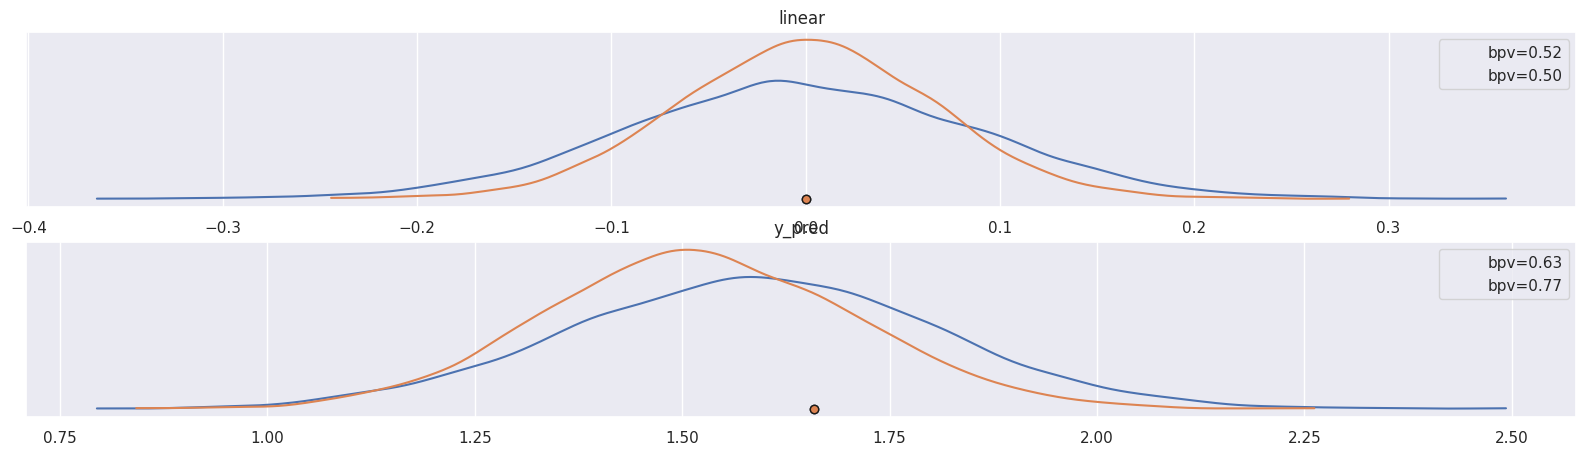

In [13]:
colors = ["C0", "C1"]
idatas = [idata_l, idata_q]
fig, axes = plt.subplots(2, 1)

# Plot the Bayesian p-value for the mean, for both models.
for idata, c in zip(idatas, colors):
    az.plot_bpv(idata, kind="t_stat", t_stat="mean", ax=axes[0], color=c)
    axes[0].set_title("linear")

# Plot the Bayesian p-value for the interquartile range, for both models.
for idata, c in zip(idatas, colors):
    az.plot_bpv(idata, kind="t_stat", t_stat=utils.iqr, ax=axes[1], color=c)

## Cell 1.7: Bayesian p-value for the entire distribution

**Goal**
- Compare the Bayesian p-value across the entire predictive distribution,
  not just one summary statistic

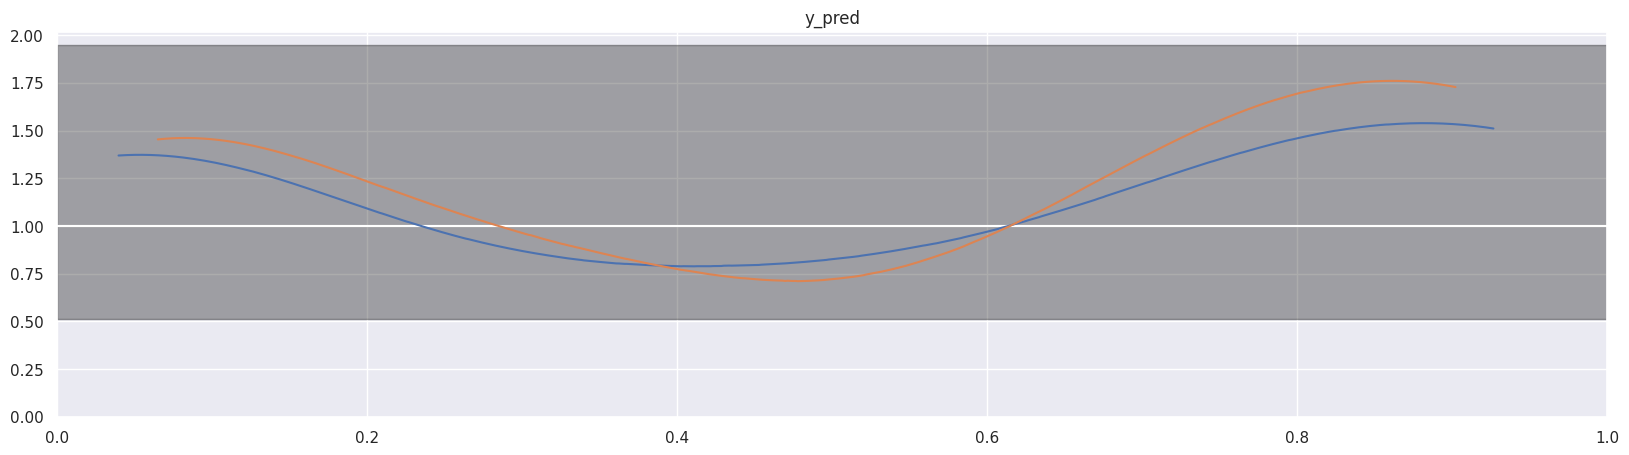

In [14]:
fig, ax = plt.subplots()
for idata, c in zip(idatas, colors):
    az.plot_bpv(idata, color=c, ax=ax)

# Part 2: Overfitting

## Cell 2.1: In-sample vs out-of-sample data

**Goal**
- Set up a small in-sample dataset and a separate out-of-sample dataset,
  used next to show how model complexity trades off against overfitting

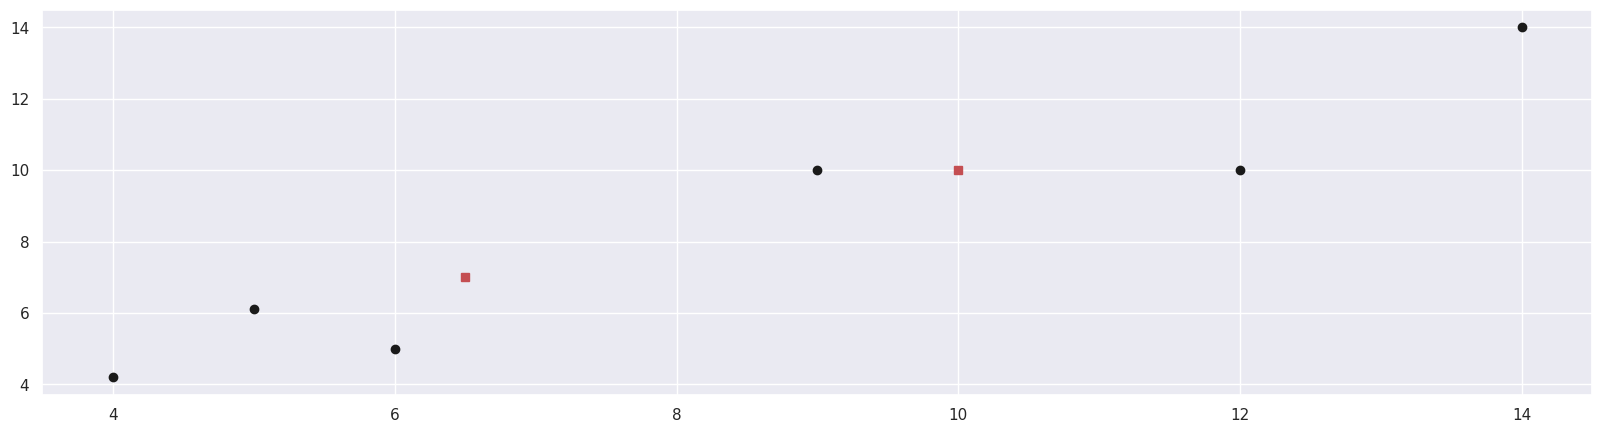

In [15]:
x0 = np.array([4.0, 5.0, 6.0, 9.0, 12, 14.0])
y0 = np.array([4.2, 6.1, 5.0, 10.0, 10, 14.0])
x1 = np.array([6.5, 10])
y1 = np.array([7, 10])

_, ax = plt.subplots(1, 1)
ax.plot(x0, y0, "ko")
_ = ax.plot(x1, y1, "rs")

## Cell 2.2: Fitting polynomial models of increasing order

**Goal**
- Fit polynomials of order 0, 1, and 5 on the in-sample data, and read
  off each one's $R^2$

**Implementation** `utils.plot_models(ax, x_n, x0, y0, order, ps)`
- Fits each order with `np.polynomial.Polynomial.fit()`, then plots the
  fitted curve and its $R^2$ against `(x0, y0)`

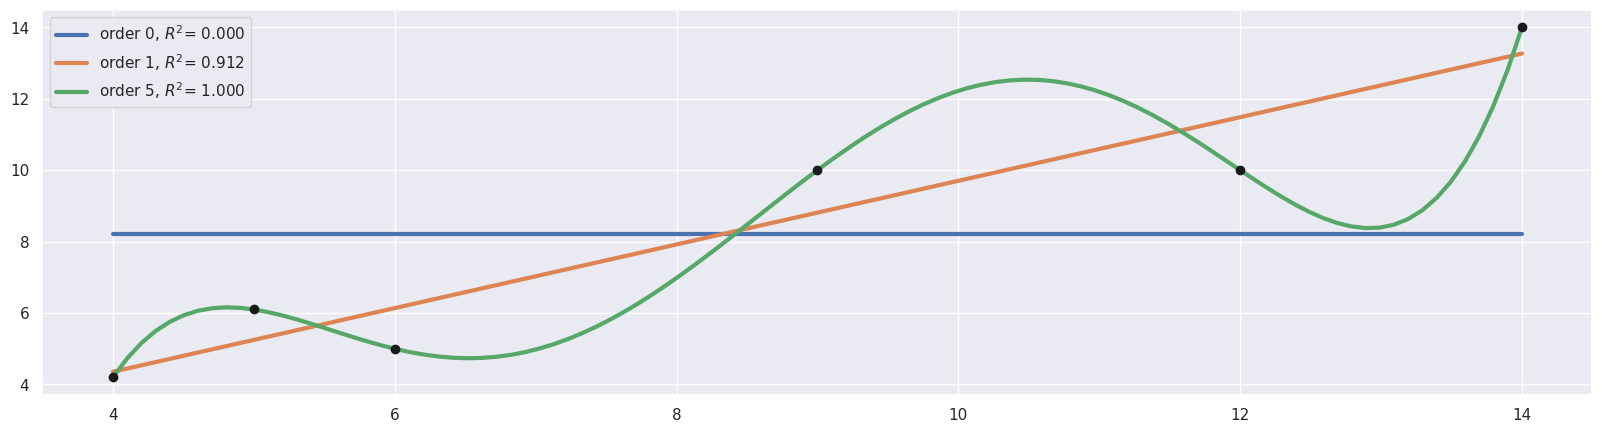

In [16]:
_, ax = plt.subplots(1, 1)
ax.plot(x0, y0, "ko", zorder=3)

# Learn 3 models.
order_list = [0, 1, 5]
x_n = np.linspace(x0.min(), x0.max(), 100)
ps = [np.polynomial.Polynomial.fit(x0, y0, deg=i) for i in order_list]
utils.plot_models(ax, x_n, x0, y0, order_list, ps)

## Cell 2.3: Evaluating the fit on out-of-sample data

**Goal**
- Score the same 3 fitted models against the combined in-sample plus
  out-of-sample data, to see which order actually generalizes

**Implementation** `utils.plot_models(...)`, now scored against the
combined dataset instead of only the in-sample one

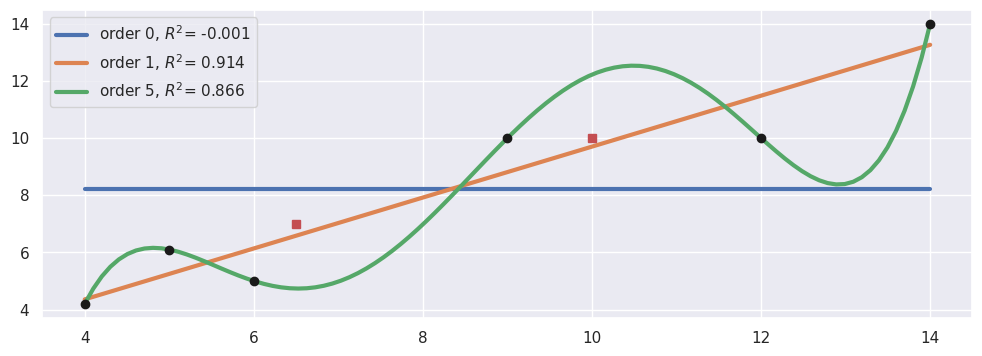

In [17]:
_, ax = plt.subplots(figsize=(12, 4))
ax.plot(x0, y0, "ko", zorder=3)
ax.plot(x1, y1, "rs", zorder=3)

x_all = np.concatenate((x0, x1))
y_all = np.concatenate((y0, y1))
utils.plot_models(ax, x_n, x_all, y_all, order_list, ps)

## Cell 2.4: Calculating predictive accuracy

**Goal**
- Compute two out-of-sample predictive-accuracy estimates, WAIC and PSIS-
  LOO, for the linear and quadratic Bayesian models from Part 1

**Implementation** `az.waic(idata)` and `az.loo(idata)`

In [18]:
waic_l = az.waic(idata_l)
display(waic_l)

Computed from 8000 posterior samples and 33 observations log-likelihood matrix.

          Estimate       SE
elpd_waic   -14.25     2.65
p_waic        2.36        -

In [19]:
waic_q = az.waic(idata_q)
display(waic_q)

Computed from 8000 posterior samples and 33 observations log-likelihood matrix.

          Estimate       SE
elpd_waic    -4.61     2.34
p_waic        2.68        -

In [20]:
loo_l = az.loo(idata_l)
display(loo_l)

Computed from 8000 posterior samples and 33 observations log-likelihood matrix.

         Estimate       SE
elpd_loo   -14.28     2.65
p_loo        2.38        -
------

Pareto k diagnostic values:
                         Count   Pct.
(-Inf, 0.70]   (good)       33  100.0%
   (0.70, 1]   (bad)         0    0.0%
   (1, Inf)   (very bad)    0    0.0%

In [21]:
loo_q = az.loo(idata_q)
display(loo_q)

Computed from 8000 posterior samples and 33 observations log-likelihood matrix.

         Estimate       SE
elpd_loo    -4.64     2.35
p_loo        2.71        -
------

Pareto k diagnostic values:
                         Count   Pct.
(-Inf, 0.70]   (good)       33  100.0%
   (0.70, 1]   (bad)         0    0.0%
   (1, Inf)   (very bad)    0    0.0%

# Part 3: Comparing and Averaging Models

## Cell 3.1: Comparing models

**Goal**
- Rank the linear and quadratic model by predictive accuracy, with
  `az.compare()`'s standard-error-aware comparison

**Implementation** `az.compare({...})`, then `az.plot_compare()`

In [22]:
cmp_df = az.compare({"model_l": idata_l, "model_q": idata_q})
display(cmp_df)

,rank,elpd_loo,p_loo,elpd_diff,weight,se,dse,warning,scale
model_q,0,-4.635657,2.707734,0.000000,1.000000e+00,2.346038,0.000000,False,log
model_l,1,-14.276130,2.382468,9.640473,6.261658e-14,2.654390,2.686804,False,log


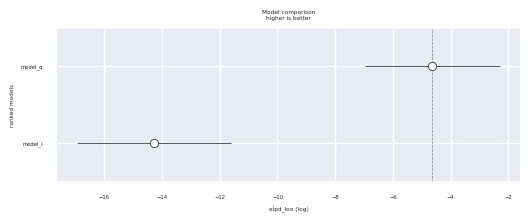

In [23]:
_ = az.plot_compare(cmp_df)

## Cell 3.2: Model averaging

**Goal**
- Combine both models' posterior predictive distributions into one
  weighted mixture, instead of picking a single "best" model

**Implementation** `az.weight_predictions(idatas, weights)`
- Weights the linear and quadratic posterior predictive by 0.35/0.65,
  then compares all three predictive densities via `az.plot_kde()`

In [24]:
idatas = [idata_l, idata_q]
weights = [0.35, 0.65]
idata_w = az.weight_predictions(idatas, weights)

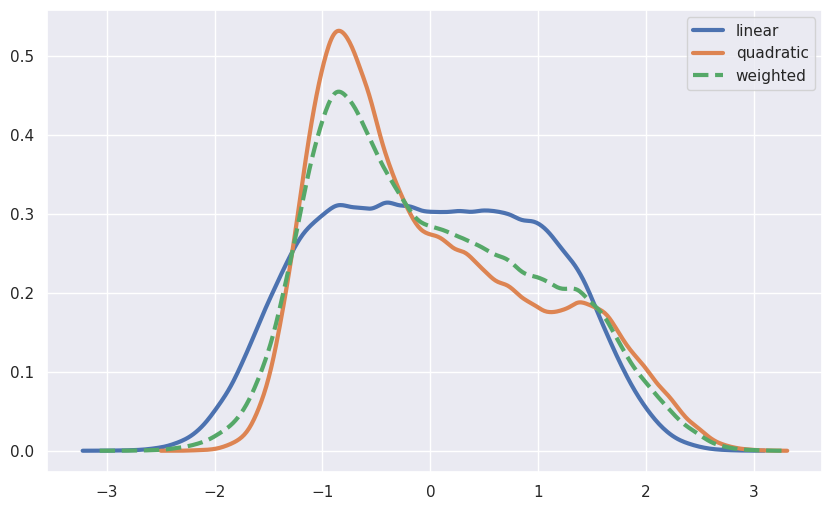

In [25]:
# Plot the KDE of the posterior predictive for each model, and the mixture.
_, ax = plt.subplots(figsize=(10, 6))

az.plot_kde(
    idata_l.posterior_predictive["y_pred"].values,
    plot_kwargs={"color": "C0", "lw": 3},
    label="linear",
    ax=ax,
)
az.plot_kde(
    idata_q.posterior_predictive["y_pred"].values,
    plot_kwargs={"color": "C1", "lw": 3},
    label="quadratic",
    ax=ax,
)
az.plot_kde(
    idata_w.posterior_predictive["y_pred"].values,
    plot_kwargs={"color": "C2", "lw": 3, "ls": "--"},
    label="weighted",
    ax=ax,
)
_ = plt.legend()

# Part 4: Mixture Models

## Cell 4.1: Marginalization over a Gaussian mixture

**Goal**
- Fit a 2-component Gaussian mixture to chemical-shift data, marginalizing
  over a discrete latent component label for every point

**Implementation**
- `p ~ Dirichlet([1, 1])` picks the mixture weights, `z ~ Categorical(p)`
  assigns each point a component, and `y | z ~ Normal(means[z], sd)` is
  the observed likelihood; all three are estimated jointly

In [26]:
!ls $dir_name

anscombe.csv	     chemical_shifts_theo_exp.csv  islands.csv
anscombe_3.csv	     coal.csv			   penguins.csv
babies.csv	     dummy.csv			   pigs.csv
bikes.csv	     fish.csv			   redwood.csv
bikes_full.csv	     football_players.csv	   space_flu.csv
body_fat.csv	     horseshoe_crab.csv		   tips.csv
body_fat_full.csv    howell.csv
chemical_shifts.csv  iris.csv


In [27]:
cs = pd.read_csv(dir_name + "/chemical_shifts_theo_exp.csv")
cs_exp = pd.DataFrame(cs["exp"])
display(cs_exp.head())
print("shape=", len(cs_exp))

,exp
0,58.27
1,56.18
2,56.84
3,51.01
4,54.64


shape= 1776


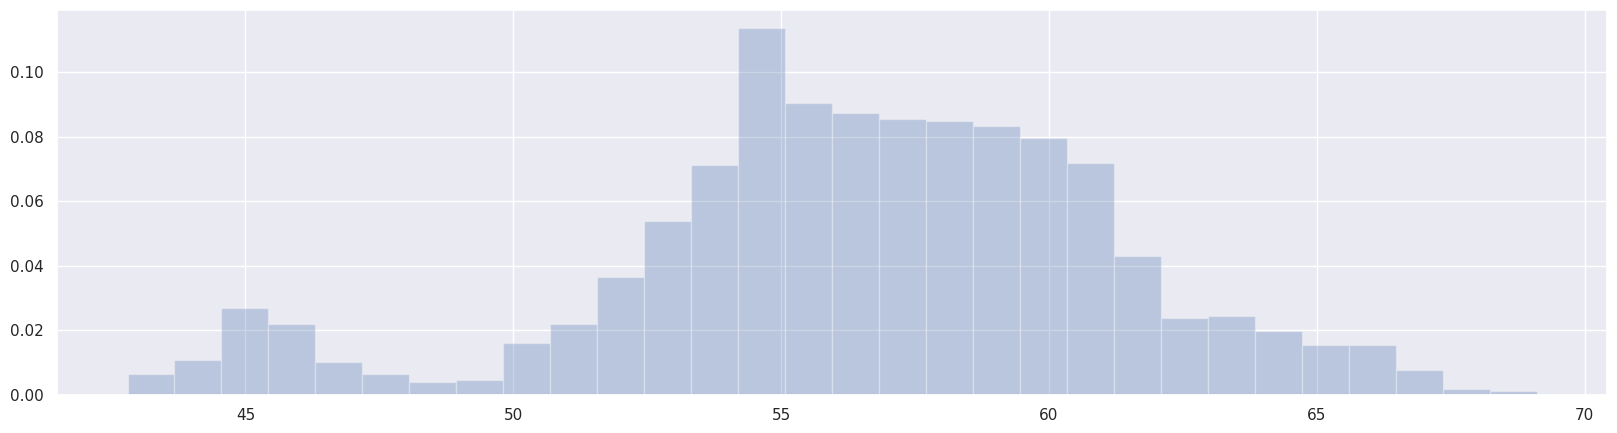

In [28]:
_, ax = plt.subplots()
_ = plt.hist(cs_exp, density=True, bins=30, alpha=0.3)

In [29]:
# The parameters to estimate are:
# - a latent variable (one component per data point) drawn from a Dirichlet
#   - All vars are estimated together as one hierarchical model.
# - the means and shared std dev of the 2 Gaussian components
K = 2
with pm.Model() as model_kg:
    # Prior p ~ Dirichlet([1, 1]), which is a Beta.
    p = pm.Dirichlet("p", a=np.ones(K))
    # Assign each data point a component via the latent variable "z".
    z = pm.Categorical("z", p=p, shape=len(cs_exp))
    # 2 Gaussians with different mean and same std.
    #means = pm.Normal("means", mu=cs_exp.mean(), sigma=10, shape=K)
    means = pm.Normal("means", mu=cs_exp["exp"].mean(), sigma=10, shape=K)
    sd = pm.HalfNormal("sd", sigma=10)
    # The distribution is a Gaussian whose mean is a function of z.
    #y = pm.Normal("y", mu=means[z], sigma=sd, observed=cs_exp)
    y = pm.Normal("y", mu=means[z], sigma=sd, observed=cs_exp["exp"].values)
    trace_kg = pm.sample()

Multiprocess sampling (4 chains in 4 jobs)


INFO  Multiprocess sampling (4 chains in 4 jobs)


CompoundStep


INFO  CompoundStep


>NUTS: [p, means, sd]


INFO  >NUTS: [p, means, sd]


... (2 outputs left out)

Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 110 seconds.


INFO  Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 110 seconds.


/venv/lib/python3.12/site-packages/arviz/stats/diagnostics.py:596: RuntimeWarning: invalid value encountered in scalar divide
  (between_chain_variance / within_chain_variance + num_samples - 1) / (num_samples)


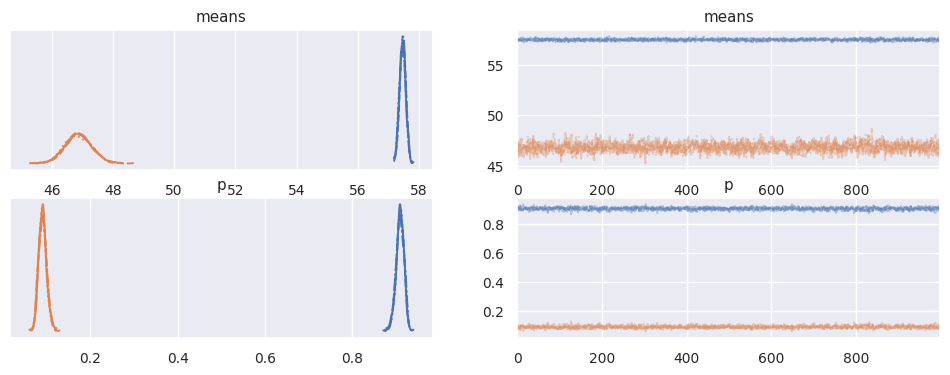

In [30]:
varnames = ["means", "p"]
_ = az.plot_trace(trace_kg, varnames)

# Part 5: Inference Engines

## Cell 5.1: Grid approximation

**Goal**
- Estimate a coin-flip posterior by brute-force grid approximation: a
  uniform prior times a Binomial likelihood, normalized over a grid

**Implementation** `utils.posterior_grid(grid_points, heads, tails)`

heads= 3
tails= 10


/venv/lib/python3.12/site-packages/numba/np/ufunc/dufunc.py:290: RuntimeWarning: divide by zero encountered in nb_logpdf
  return super().__call__(*args, **kws)


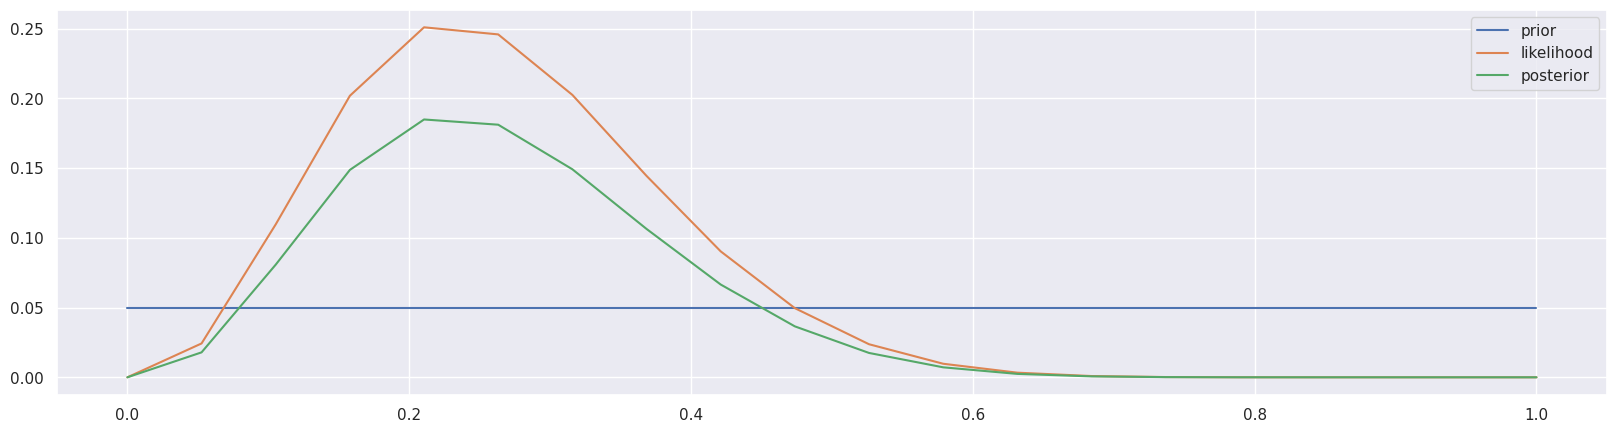

In [31]:
heads = 3
tails = 10
grid_points = 20

print("heads=", heads)
print("tails=", tails)
grid, prior, likelihood, posterior = utils.posterior_grid(
    grid_points, heads, tails
)

# Plot posterior.
plt.plot(grid, prior, label="prior")
plt.plot(grid, likelihood, label="likelihood")
plt.plot(grid, posterior, label="posterior")
_ = plt.legend()

## Cell 5.2: Monte Carlo estimate of pi

**Goal**
- Estimate pi by the classic dartboard Monte Carlo method: the fraction
  of random points inside the unit circle approximates pi/4

**Implementation**
- Draws `N` uniform 2D points in $[-1, 1]^2$ and checks which fall inside
  the unit circle

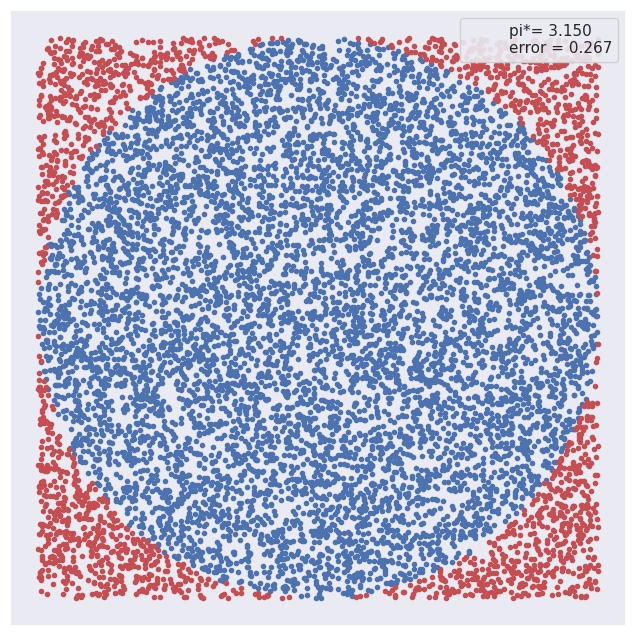

In [32]:
N = 10000
x_mc, y_mc = np.random.uniform(-1, 1, size=(2, N))
inside = (x_mc**2 + y_mc**2) <= 1
pi_estimate = inside.sum() * 4 / N
error = abs((pi_estimate - np.pi) / pi_estimate) * 100
outside = np.invert(inside)

plt.figure(figsize=(8, 8))
plt.plot(x_mc[inside], y_mc[inside], "b.")
plt.plot(x_mc[outside], y_mc[outside], "r.")
plt.plot(0, 0, label=f"pi*= {pi_estimate:4.3f}\nerror = {error:4.3f}", alpha=0)
plt.axis("square")
plt.xticks([])
plt.yticks([])
_ = plt.legend(loc=1, frameon=True, framealpha=0.9)

## Cell 5.3: Metropolis sampler

**Goal**
- Implement the Metropolis algorithm from scratch, and check that it
  recovers a known Beta(2, 5) target density

**Implementation** `utils.metropolis(func, draws)`
- Proposes a Gaussian random-walk step, accepts it with probability
  `min(1, new_prob / old_prob)`, and repeats it otherwise

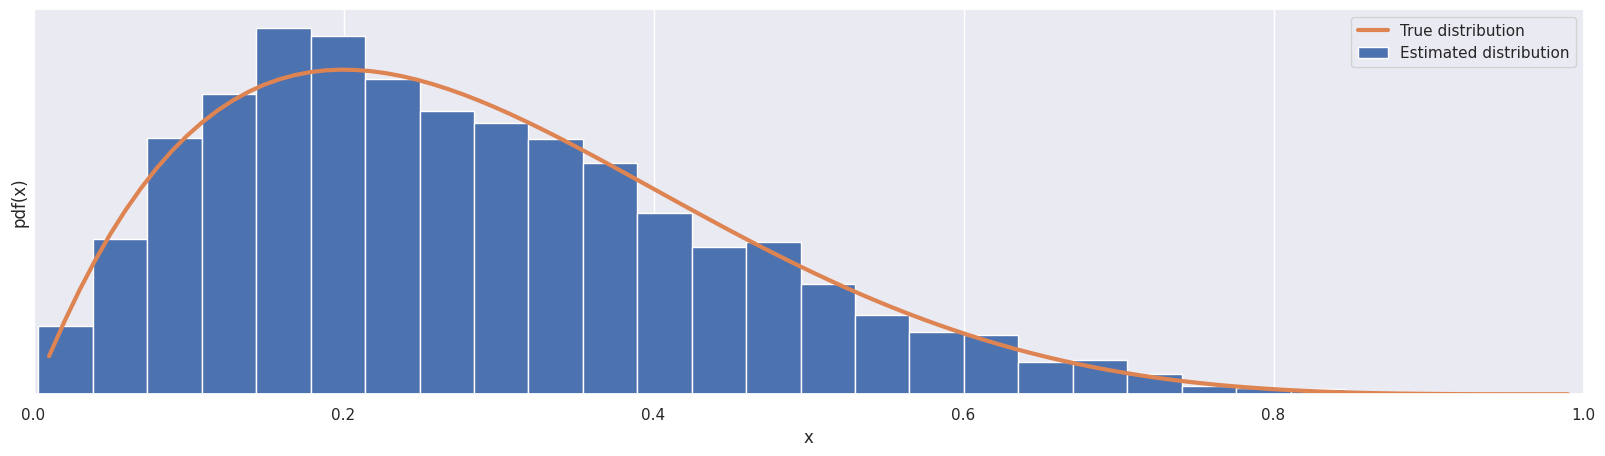

In [33]:
np.random.seed(3)
func = stats.beta(2, 5)
trace = utils.metropolis(func=func)
x_grid = np.linspace(0.01, 0.99, 100)
y_grid = func.pdf(x_grid)
plt.xlim(0, 1)
plt.plot(x_grid, y_grid, "C1-", lw=3, label="True distribution")
plt.hist(trace[trace > 0], bins=25, density=True, label="Estimated distribution")
plt.xlabel("x")
plt.ylabel("pdf(x)")
plt.yticks([])
plt.legend()
plt.savefig("B11197_08_05.png")

# Part 6: Diagnosing Convergence

## Cell 6.1: Centered vs non-centered parametrization

**Goal**
- Fit the same hierarchical model in two equivalent parametrizations,
  centered and non-centered, and compare their sampling traces

**Implementation**
- `model_c`: `b ~ Normal(0, a)` directly (centered)
- `model_nc`: `b = b_offset * a` with `b_offset ~ Normal(0, 1)`
  (non-centered, easier for NUTS to sample when `a` is small)

In [34]:
# Centered model.
with pm.Model() as model_c:
    # Param for the std dev of all Gaussians.
    a = pm.HalfNormal("a", 10)
    # 10 normals with mean=0 and std dev=a.
    b = pm.Normal("b", 0, a, shape=10)
    idata_c = pm.sample(random_seed=73)

Initializing NUTS using jitter+adapt_diag...


INFO  Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


INFO  Multiprocess sampling (4 chains in 4 jobs)


NUTS: [a, b]


INFO  NUTS: [a, b]


... (5 outputs left out)

The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


INFO  The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


ERROR The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


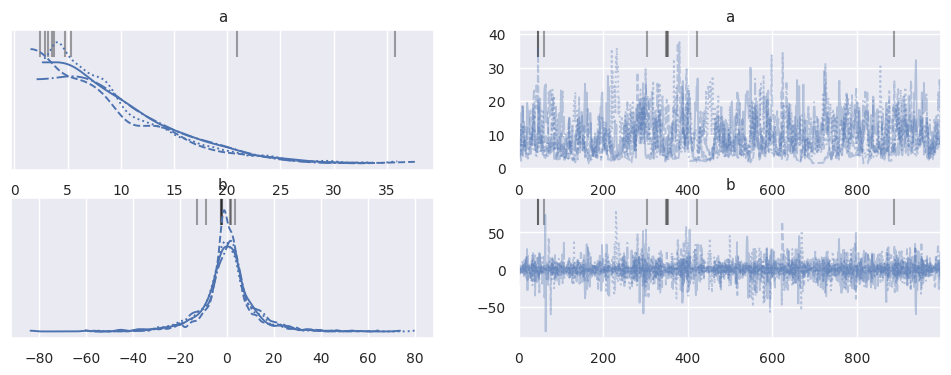

In [35]:
coords = {"b_dim_0": [0]}
_ = az.plot_trace(
    idata_c, var_names=["a", "b"], coords=coords, divergences="top"
)

In [36]:
# Non-centered (re-parametrized) model.
with pm.Model() as model_nc:
    a = pm.HalfNormal("a", 10)
    b_offset = pm.Normal("b_offset", mu=0, sigma=1, shape=10)
    # Gaussians are rescaled.
    b = pm.Deterministic("b", 0 + b_offset * a)
    idata_nc = pm.sample(random_seed=73)

Initializing NUTS using jitter+adapt_diag...


INFO  Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


INFO  Multiprocess sampling (4 chains in 4 jobs)


NUTS: [a, b_offset]


INFO  NUTS: [a, b_offset]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 0 seconds.


INFO  Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 0 seconds.


There was 1 divergence after tuning. Increase `target_accept` or reparameterize.


ERROR There was 1 divergence after tuning. Increase `target_accept` or reparameterize.


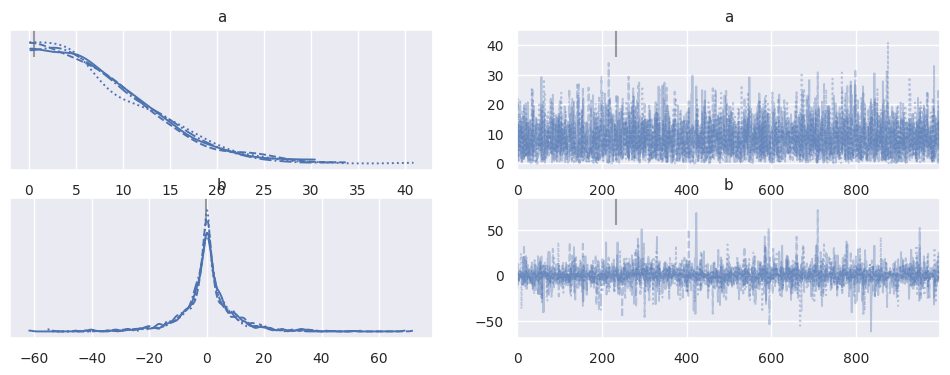

In [37]:
ax = az.plot_trace(
    idata_nc, var_names=["a", "b"], coords=coords, divergences="top"
)

## Cell 6.2: Rank plots

**Goal**
- Read the same centered-vs-non-centered comparison off rank plots, a
  diagnostic that is easier to read than overlaid trace lines for many
  chains

**Implementation** `az.plot_trace(idata, kind="rank_bars", ...)`

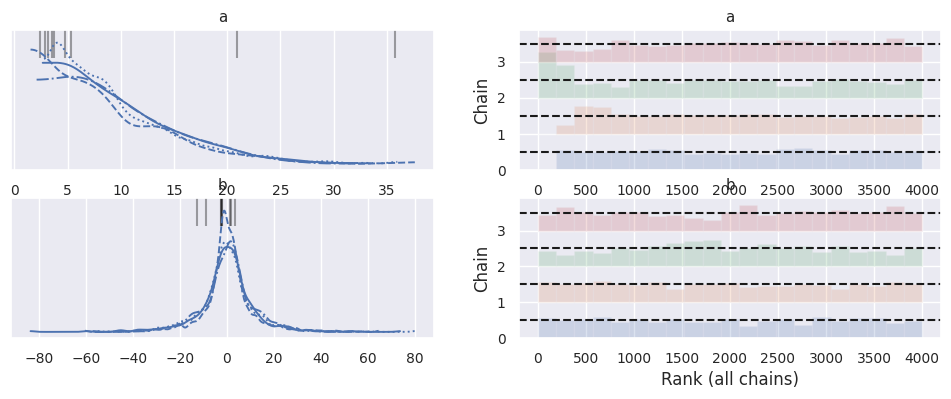

In [38]:
_ = az.plot_trace(
    idata_c,
    var_names=["a", "b"],
    divergences="top",
    kind="rank_bars",
    coords=coords,
)

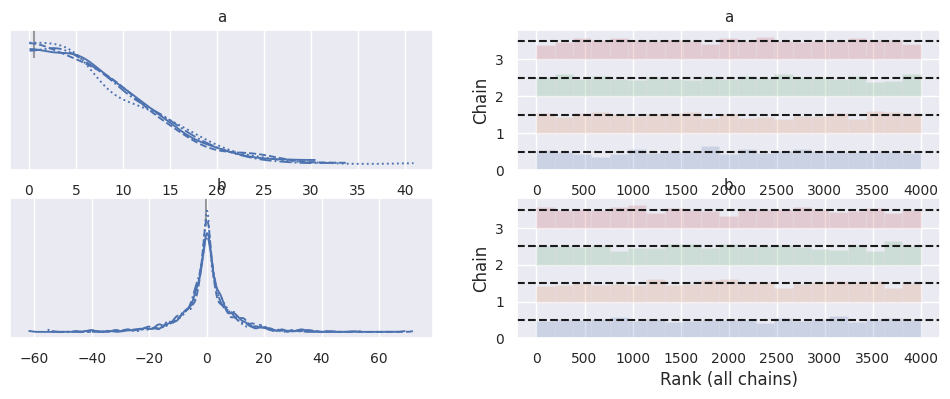

In [39]:
_ = az.plot_trace(
    idata_nc,
    var_names=["a", "b"],
    divergences="top",
    kind="rank_bars",
    coords=coords,
)

## Cell 6.3: R-hat

**Goal**
- Compare the centered and non-centered fits' summary statistics and
  R-hat convergence diagnostic side by side

In [40]:
summaries = pd.concat(
    [az.summary(idata_c, var_names=["a"]), az.summary(idata_nc, var_names=["a"])]
)
summaries.index = ["centered", "non_centered"]
display(summaries)

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
centered,9.196,5.628,1.484,19.635,0.316,0.166,226.0,96.0,1.02
non_centered,8.004,5.989,0.001,18.594,0.089,0.096,3203.0,1930.0,1.00


In [41]:
display(az.rhat(idata_c, var_names="a b".split()).to_dataframe().T)

b_dim_0,0,1,2,3,4,5,6,7,8,9
a,1.020917,1.020917,1.020917,1.020917,1.020917,1.020917,1.020917,1.020917,1.020917,1.020917
b,1.007797,1.007311,1.002690,1.006034,1.005417,1.005621,1.007139,1.008204,1.008591,1.005970


In [42]:
display(az.rhat(idata_nc, var_names="a b".split()).to_dataframe().T)

b_dim_0,0,1,2,3,4,5,6,7,8,9
a,1.000227,1.000227,1.000227,1.000227,1.000227,1.000227,1.000227,1.000227,1.000227,1.000227
b,1.000062,1.001095,1.000055,0.999844,1.001604,1.001224,1.000371,1.000984,1.001622,1.000192


## Cell 6.4: Effective sample size (ESS)

**Goal**
- Compare autocorrelation and effective sample size between the two
  parametrizations: the non-centered one should mix better

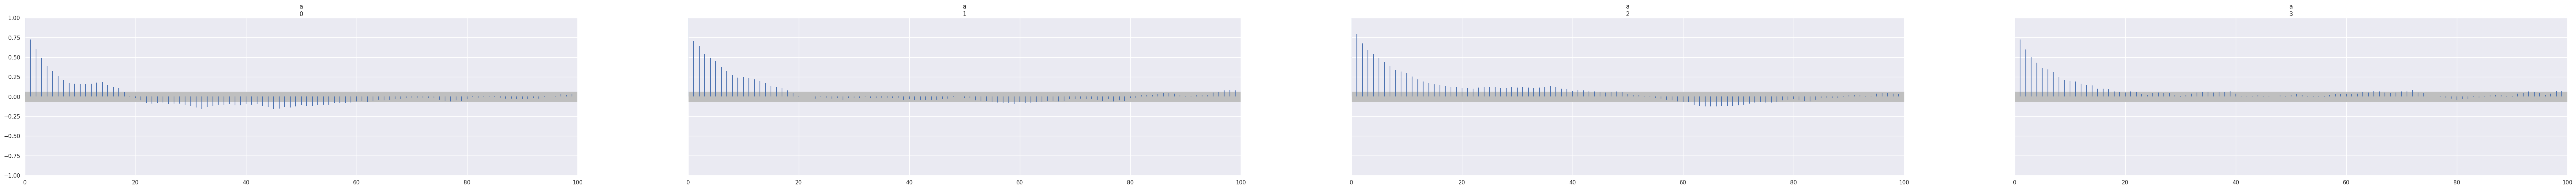

In [43]:
_ = az.plot_autocorr(idata_c, var_names=["a"])

In [44]:
display(az.ess(idata_c, var_names="a b".split()).to_dataframe().T)

b_dim_0,0,1,2,3,4,5,6,7,8,9
a,226.087845,226.087845,226.087845,226.087845,226.087845,226.087845,226.087845,226.087845,226.087845,226.087845
b,5276.869004,5543.649435,4277.922488,5537.329821,5276.848943,4861.116291,4361.498547,5120.809758,5431.882555,4661.260890


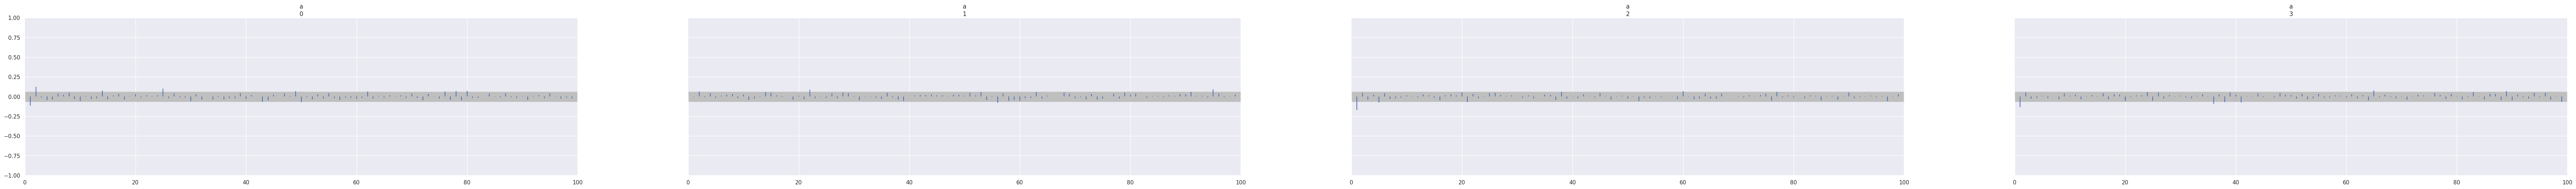

In [45]:
_ = az.plot_autocorr(idata_nc, var_names=["a"])

In [46]:
display(az.ess(idata_nc, var_names="a b".split()).to_dataframe().T)

b_dim_0,0,1,2,3,4,5,6,7,8,9
a,3202.762089,3202.762089,3202.762089,3202.762089,3202.762089,3202.762089,3202.762089,3202.762089,3202.762089,3202.762089
b,4882.437611,4604.116707,5667.519879,5581.517483,4787.824791,4506.078676,5009.864240,4404.443838,5063.283265,4494.229302


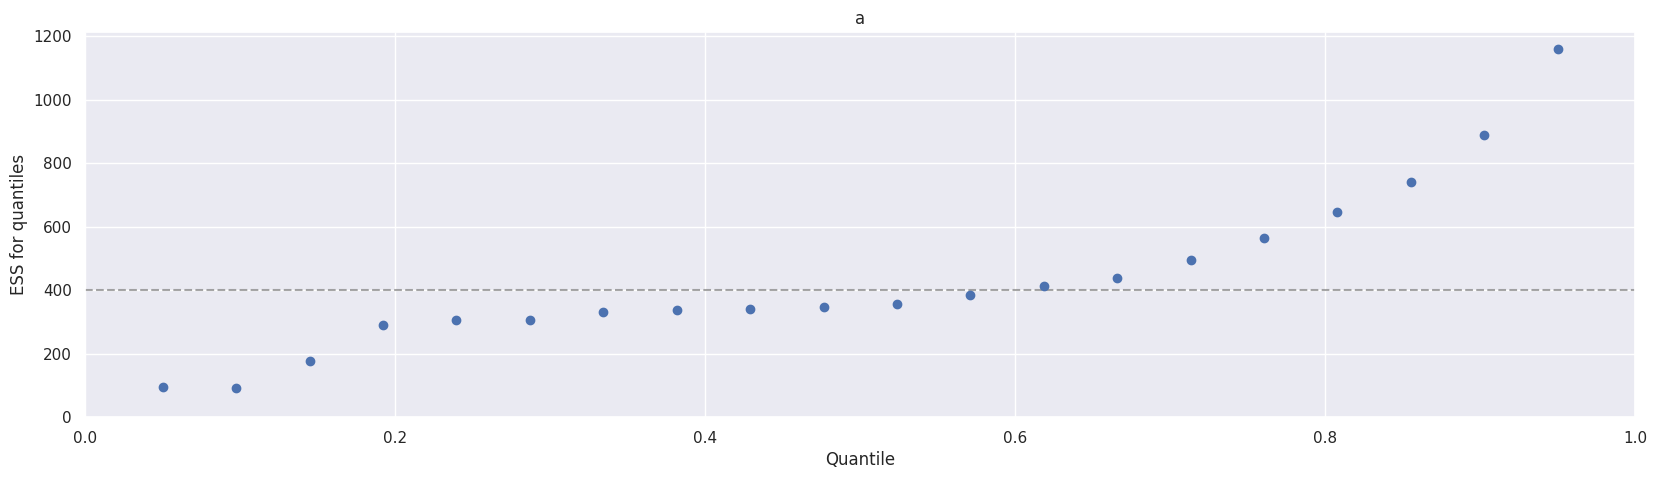

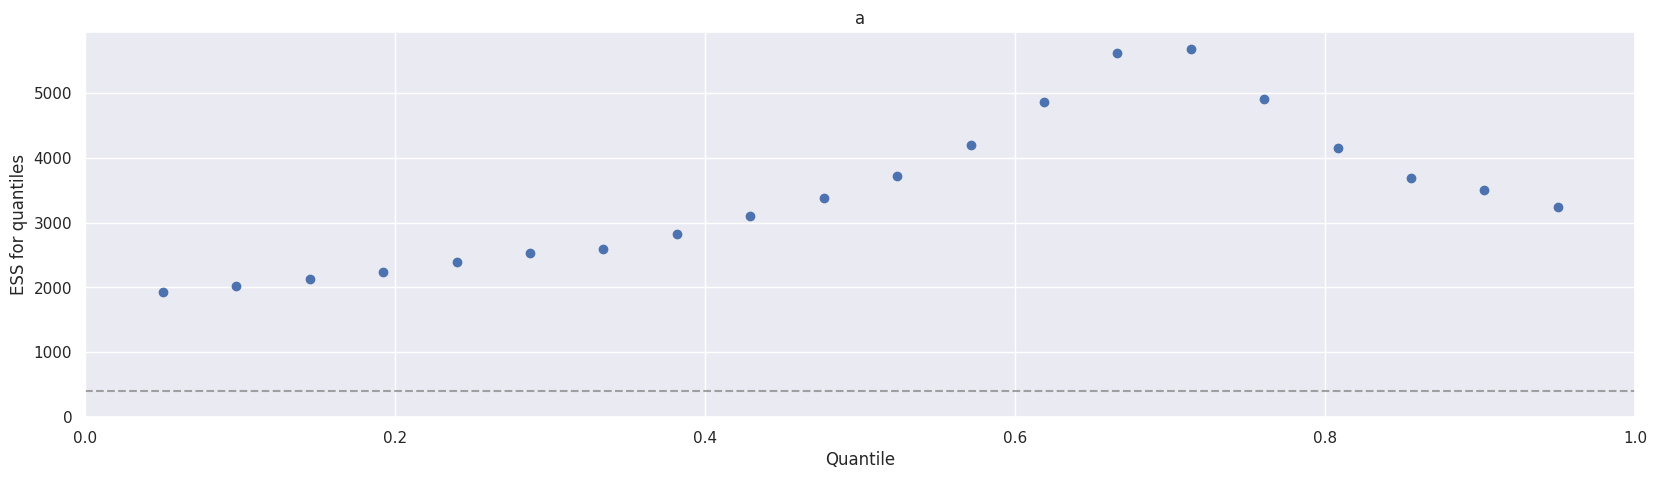

In [47]:
# Plot the ESS by quantile.
az.plot_ess(idata_c, var_names="a", kind="quantile")
_ = az.plot_ess(idata_nc, var_names="a", kind="quantile")

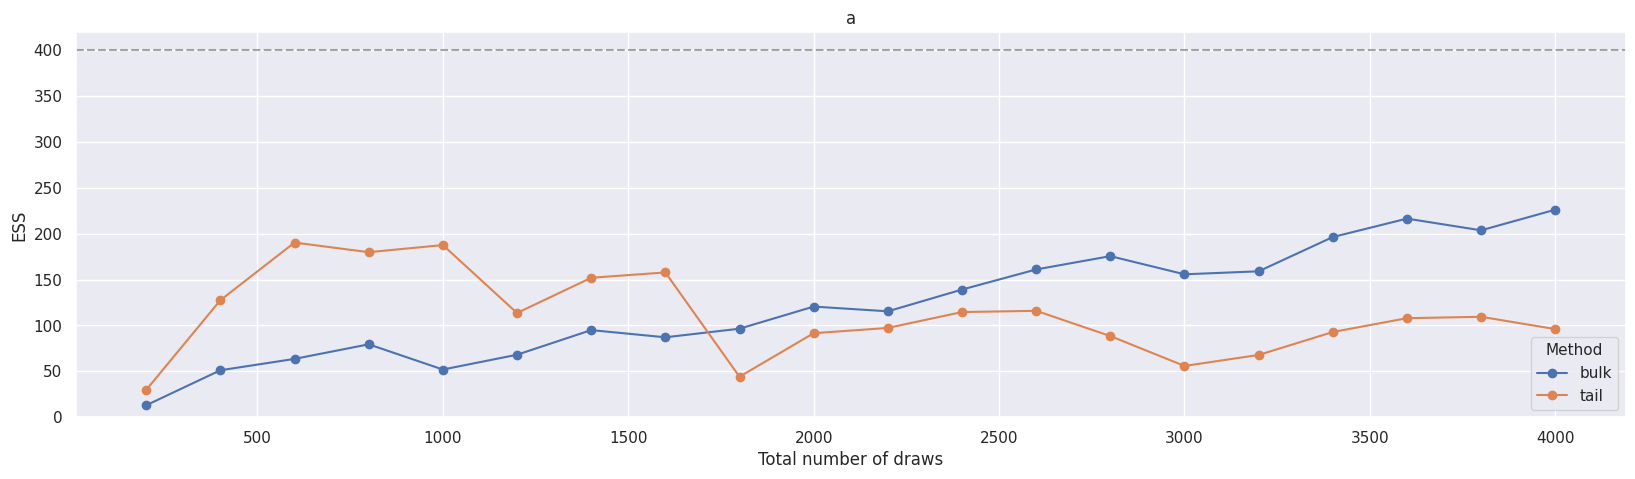

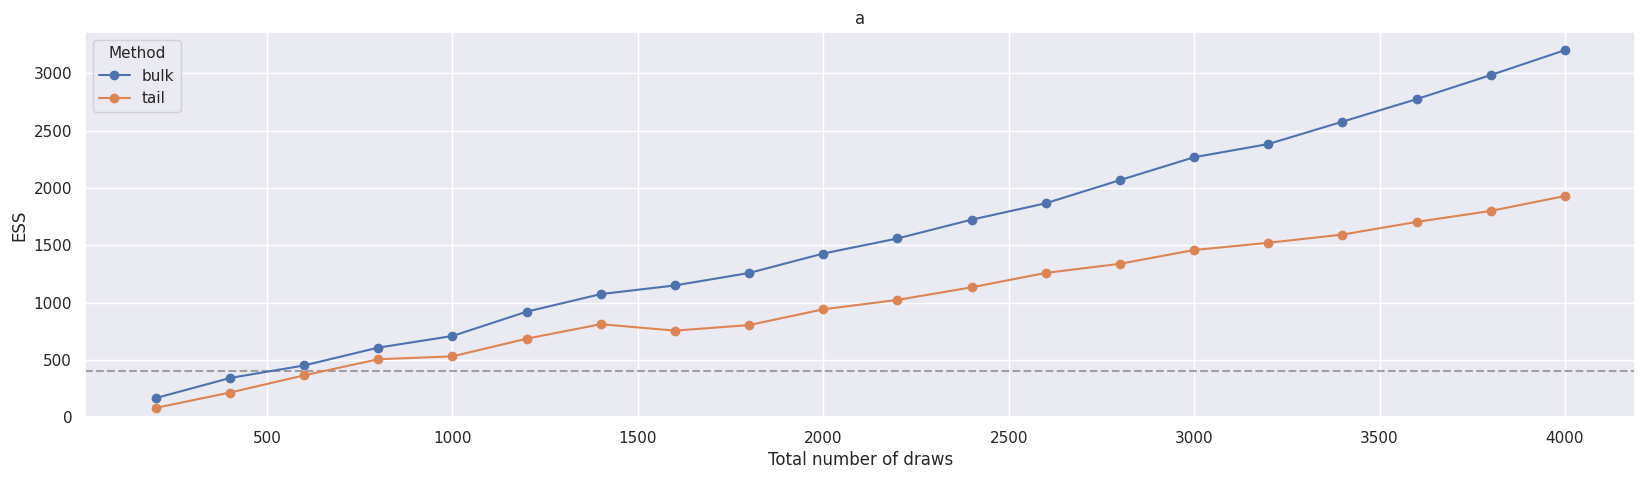

In [48]:
az.plot_ess(idata_c, var_names="a", kind="evolution")
_ = az.plot_ess(idata_nc, var_names="a", kind="evolution")

## Cell 6.5: Divergences

**Goal**
- Visualize where divergent transitions land in parameter space, for
  both parametrizations, and check `a`'s marginal for both at once

**Implementation** `az.plot_pair(..., divergences=True)` and
`az.plot_parallel()`

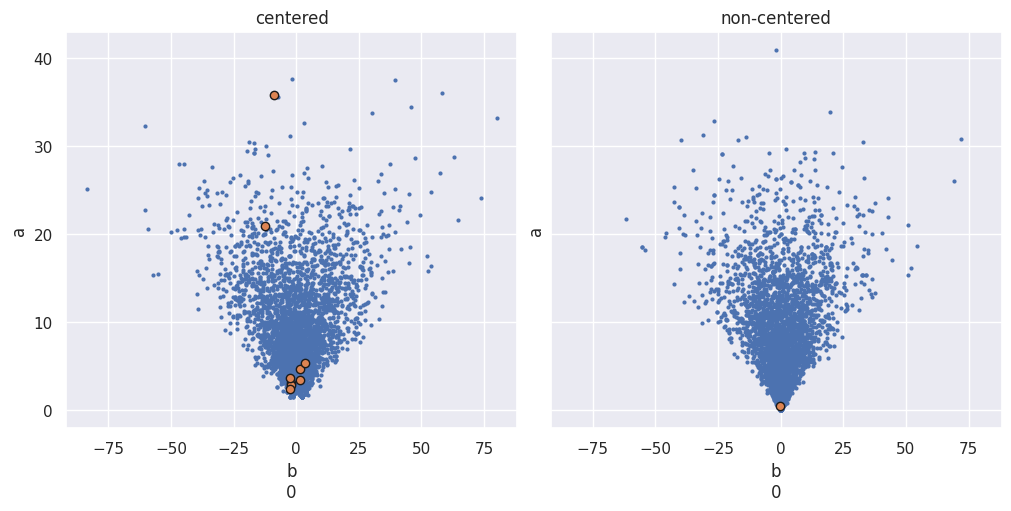

In [49]:
_, ax = plt.subplots(
    1, 2, sharey=True, sharex=True, figsize=(10, 5), constrained_layout=True
)
for idx, tr in enumerate([idata_c, idata_nc]):
    az.plot_pair(
        tr,
        var_names=["b", "a"],
        coords={"b_dim_0": [0]},
        kind="scatter",
        divergences=True,
        divergences_kwargs={"color": "C1"},
        ax=ax[idx],
    )
    ax[idx].set_title(["centered", "non-centered"][idx])

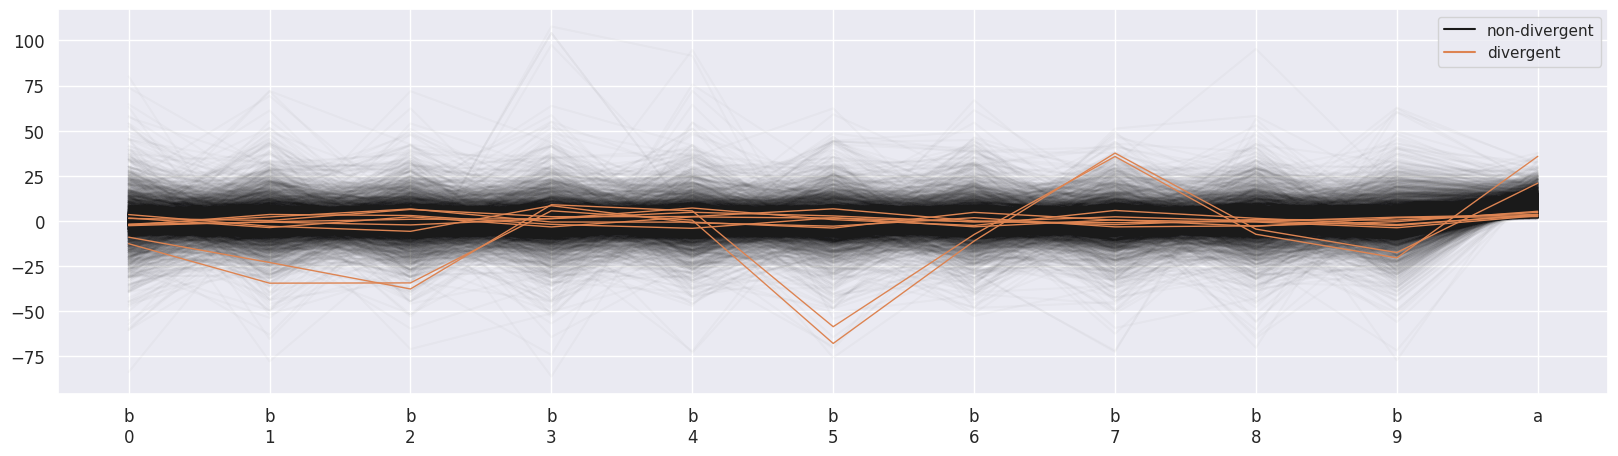

In [50]:
_ = az.plot_parallel(idata_c)

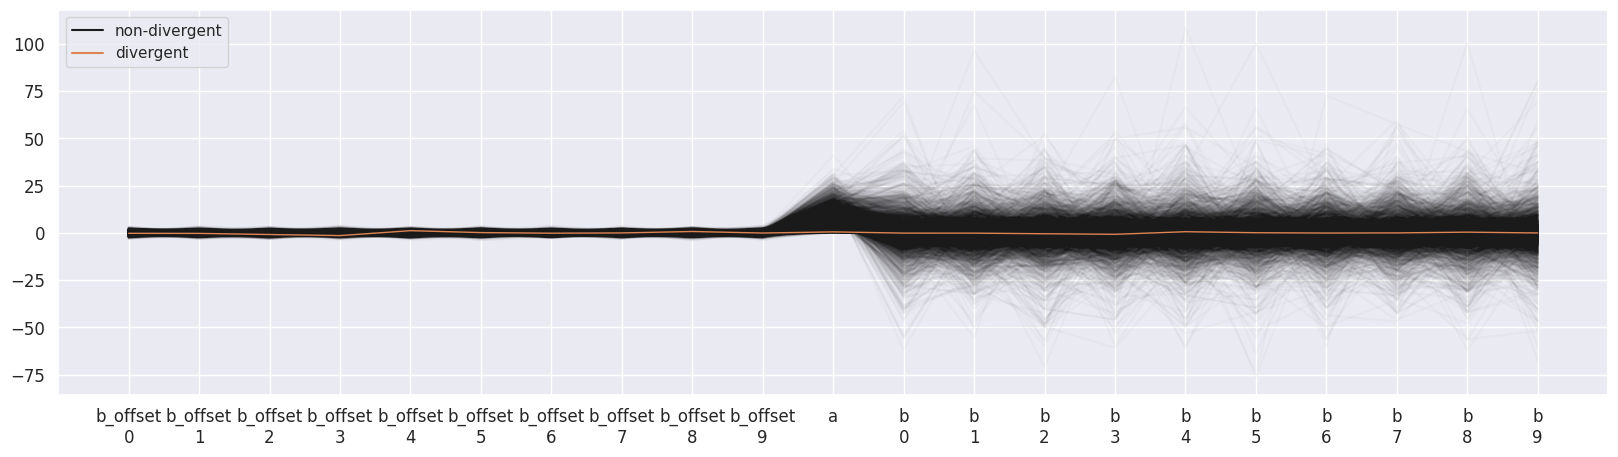

In [51]:
_ = az.plot_parallel(idata_nc)